# ESS 배터리 수명 예측 — Day 1 : EDA & 모델 설계 전략

- **데이터** : MIT-Stanford Battery Dataset (Severson et al., *Nature Energy* 2019) · A123 LFP/graphite 18650, 공칭 1.1Ah
- **과제 구성** : Batch 1 = 2017-05-12 (학습) · Batch 2 = 2018-02-20 (테스트) · Batch 3 = 2018-04-12 (추가 검증)
- **선택 태스크** : **Regression** — 초기 100 사이클로 `cycle_life` 예측 · Target = `log10(cycle_life)` · Metric = MAPE · 원논문 목표 **9.1%**
- **활용 관점** : 운전 초기(100 사이클) 데이터만으로 셀별 수명을 예측해, ESS 설치 전 셀 선별과 교체 계획(ESS CAPEX의 30~40%)에 활용합니다.

---

### 핵심 요약 (EDA → 전략)

| # | EDA 핵심 발견 | 모델링 결정 |
|---|---|---|
| 1 | 550 기준 단수명 셀이 **Batch 1에는 41개 중 1개**, Batch 2에는 30개 | 분류 대신 **회귀** 선택 |
| 2 | Batch 2 standard 셀 30개의 수명(392~514)이 **모두 Batch 1 최솟값(534)보다 짧음** | 학습 범위 밖 **외삽이 가능한 선형 모델** 우선, 트리 모델은 비교군 |
| 3 | 초기 100 사이클의 QD는 셀 간 차이가 거의 없고, knee는 수명의 약 75% 지점에서 발생 | 초기 QD 대신 **ΔQ(V) 곡선 기반 피처** 사용 |
| 4 | `log var(ΔQ₁₀₀₋₁₀)` 가 **세 배치 모두** 수명과 강한 음의 상관 (r = −0.95 / −0.90 / −0.80) | **핵심 피처**로 채택 |
| 5 | 충전 정책·IR·평균 온도는 배치마다 상관 부호가 바뀜 · B2/B3는 평균 4.8C로 고정인데 수명이 약 5배 차이 | 정책 피처는 **배치 특이적** → 기본 제외, **배치 간 부호가 일관된 피처(F2)** 를 주 피처셋으로 사용 |

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.preprocess import load_processed, EOL_AH
from src.features import build_feature_table, delta_q_matrix, knee_table, fade_rate, vif

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'figure.figsize': (13, 4.5), 'font.size': 11, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

# 분석 그룹 : Batch 2 는 시험 구조(policy_group)가 다른 두 집단으로 나누어 분석
GROUP_COLOR = {'B1': '#3B6EA8', 'B2-standard': '#D1495B', 'B2-newstructure': '#F4A259', 'B3': '#2E9E6B'}
GROUPS = list(GROUP_COLOR)

In [2]:
# 전처리 캐시 로드 (src/preprocess.py : 원본 .mat 7.7GB 에서 분석에 필요한 필드만 추출)
cells, summary, qd = load_processed()                              # 분석용 (제외 셀 미포함)
cells_all, summary_all, _ = load_processed(include_excluded=True)  # 제외 셀 포함

cells['group'] = np.where(cells['batch'] == 2, 'B2-' + cells['policy_group'], 'B' + cells['batch'].astype(str))

# 셀 단위 피처 테이블 (초기 100 사이클, ΔQ_100-10)
feat = build_feature_table(cells, summary, qd, n_cycles=100)
feat = feat.merge(cells[['cell_key', 'group', 'curve_truncated']], on='cell_key')
feat['log_life'] = np.log10(feat['cycle_life'])

summary = summary.merge(cells[['cell_key', 'group', 'cycle_life', 'curve_truncated']], on='cell_key')
print(feat.groupby('group').size().reindex(GROUPS).to_dict())

{'B1': 41, 'B2-standard': 30, 'B2-newstructure': 9, 'B3': 40}


## 1. 입력 데이터 정의

**ISSUE** : 데이터가 어떻게 수집·정리되었고, Target 이 무엇이며, 누락·오류 데이터는 없는가?

- **실험** : A123 LFP/graphite 셀을 30°C 챔버에서 고속 충전(`C1(Q1)-C2` 2단 정책, 80% SOC 이후 1C CC-CV) + 4C 방전으로 반복 사이클링했습니다.
- **Target 정의** : `cycle_life` = 방전 용량(QD)이 공칭 용량의 80%(**0.88Ah**, 교체 기준 SoH 80%)에 도달한 사이클 수
- **입력(X) 후보** : 초기 100 사이클의 사이클별 요약값(QD, IR, 온도, 충전·방전 시간)과 전압축 방전 용량 곡선 `Qdlin`(1,000점)
- **정제 기준** : 원논문 공식 코드(`rdbraatz/data-driven-prediction-of-battery-cycle-life-before-capacity-degradation`)의 셀 제외·보정 규칙을 따랐습니다.

In [3]:
overview = (cells_all.groupby('batch')
            .agg(file=('batch_file', lambda x: x.iloc[0][:10]), total=('cell_key', 'size'), excluded=('exclude', 'sum')))
overview['used'] = overview['total'] - overview['excluded']
display(overview)

excluded = cells_all[cells_all['exclude']][['cell_key', 'policy', 'cycle_life_raw', 'n_cycles_summary', 'exclude_reason']]
display(excluded)

,file,total,excluded,used
batch,,,,
1,2017-05-12,46,5,41
2,2018-02-20,47,8,39
3,2018-04-12,46,6,40


,cell_key,policy,cycle_life_raw,n_cycles_summary,exclude_reason
8,b1c8,5.4C(40%)-3.6C,879.000,878,원논문 제외: 80% 용량(EOL) 미도달
10,b1c10,5.4C(50%)-3C,906.000,905,원논문 제외: 80% 용량(EOL) 미도달
12,b1c12,5.4C(50%)-3.6C,902.000,901,원논문 제외: 80% 용량(EOL) 미도달
13,b1c13,5.4C(50%)-3.6C,897.000,896,원논문 제외: 80% 용량(EOL) 미도달
22,b1c22,6C(30%)-3.6C,891.000,890,원논문 제외: 80% 용량(EOL) 미도달
68,b2c22,VarCharge-2C-100cycles,NaN,920,cycle_life 없음 (VarCharge/SLOWCYCLE 등)
69,b2c23,VarCharge-4C-100cycles,NaN,1152,cycle_life 없음 (VarCharge/SLOWCYCLE 등)
81,b2c35,VarCharge-6C-100cycles,NaN,423,cycle_life 없음 (VarCharge/SLOWCYCLE 등)
82,b2c36,VarCharge-8C-100cycles,NaN,280,cycle_life 없음 (VarCharge/SLOWCYCLE 등)
83,b2c37,3.6C(80%)-3.6C(SLOWCYCLE,NaN,101,cycle_life 없음 (VarCharge/SLOWCYCLE 등)


**[해석]**
- Batch 1 제외 5개 셀은 `cycle_life_raw ≈ 측정된 사이클 수 + 1` 입니다 → 80% 도달 전에 **시험이 중단된(우측 중도절단) 셀**이므로 제외했습니다.
- Batch 2 제외 8개는 `VarCharge`(가변 충전), `SLOWCYCLE`(저속 사이클) 실험 셀로 수명 레이블이 없습니다.
- Batch 1의 `b1c0~b1c4`는 원논문 Batch 2(2017-06-30)로 이어서 측정된 셀이므로, 공식 코드 값만큼 수명을 보정했습니다(`curve_truncated`, 열화 곡선은 Batch 1 구간까지만 존재).
- 과제의 Batch 2(`2018-02-20`)는 데이터 원본(data.matr.io)에서 *"Low rate data used to generate figure 4"* 로 분류된 **보조 실험 배치**로, 원논문의 1차 테스트셋(2017-06-30)과 다릅니다. 이 차이는 아래 EDA 전반에서 확인됩니다.

In [4]:
# 누락·오류 데이터 점검 (cycle_idx >= 1)
s1 = summary_all[summary_all.cycle_idx >= 1]
quality = pd.DataFrame({f'B{b}': {
    'rows': len(g),
    'QD 결측 (%)': g.QD.isna().mean() * 100,
    'QD 이상치 (%)': g.qd_outlier.mean() * 100,
    'IR = 0, 미측정 (%)': (g.IR == 0).mean() * 100,
    '온도 결측 (%)': g.Tavg.isna().mean() * 100,
} for b, g in s1.groupby('batch')})
display(quality)

# Target 정합성 : 레이블과 실제 QD 기록이 EOL(0.88Ah) 정의와 맞는가
last = summary.sort_values('cycle_idx').groupby('cell_key').tail(1).set_index('cell_key')
chk = cells.set_index('cell_key').assign(last_QD=last.QD)
chk['life_minus_cycles'] = chk.cycle_life - chk.n_cycles_summary
display(chk[~chk.curve_truncated].groupby('batch').agg(
    last_QD_min=('last_QD', 'min'), last_QD_max=('last_QD', 'max'),
    life_minus_cycles_median=('life_minus_cycles', 'median'),
    observed_EOL_cells=('cycle_life_observed', 'count'), cells=('cycle_life', 'size')))

,B1,B2,B3
rows,"38,765.000","26,857.000","50,961.000"
QD 결측 (%),0.000,0.000,0.000
QD 이상치 (%),0.008,0.089,0.004
"IR = 0, 미측정 (%)",0.049,18.234,0.000
온도 결측 (%),0.000,0.000,0.000


,last_QD_min,last_QD_max,life_minus_cycles_median,observed_EOL_cells,cells
batch,,,,,
1,0.880,0.883,1.000,0,36
2,0.825,0.829,-22.000,39,39
3,0.880,0.882,1.000,0,40


**[해석]**
- QD·온도 결측은 없고, QD 이상치(스파이크)는 0.1% 미만으로 매우 적습니다.
- **Batch 2 는 IR 값의 약 18% 가 0(미측정)** 입니다 → IR 은 배치 간 비교 신뢰도가 낮은 변수입니다(0 은 결측으로 처리).
- Batch 1 은 1번 사이클 데이터가 원본에 없어(QD = 0, Kaggle 데이터 노트 : "Cycle 1 data is not available") 요약 피처는 cycle_idx ≥ 1 만 사용합니다.
- **Target 정합성** : Batch 1·3 은 QD 가 0.880~0.883Ah 에 도달하면 시험을 종료해 `cycle_life = 기록 사이클 수 + 1` 입니다. Batch 2 는 0.83Ah 까지 계속 측정했으며, 39개 셀 모두 레이블이 QD 가 처음 0.88Ah 아래로 내려간 시점과 일치합니다 → **세 배치의 레이블이 같은 EOL 정의를 따릅니다.**

> **시사점 요약** : 레이블은 신뢰할 수 있으며, 결측 처리가 필요한 변수는 IR(Batch 2) 뿐입니다. 테스트 배치(2018-02-20)가 원논문 테스트셋과 다르다는 점을 성능 해석의 전제로 둡니다.

## 2. EDA

### Q1. Cycle Life 분포는 어떻게 생겼는가?

**ISSUE** : 학습(B1)과 테스트(B2)의 Target 분포가 같은가? 분류 레이블(550)이 성립하는가? Target 변환이 필요한가?

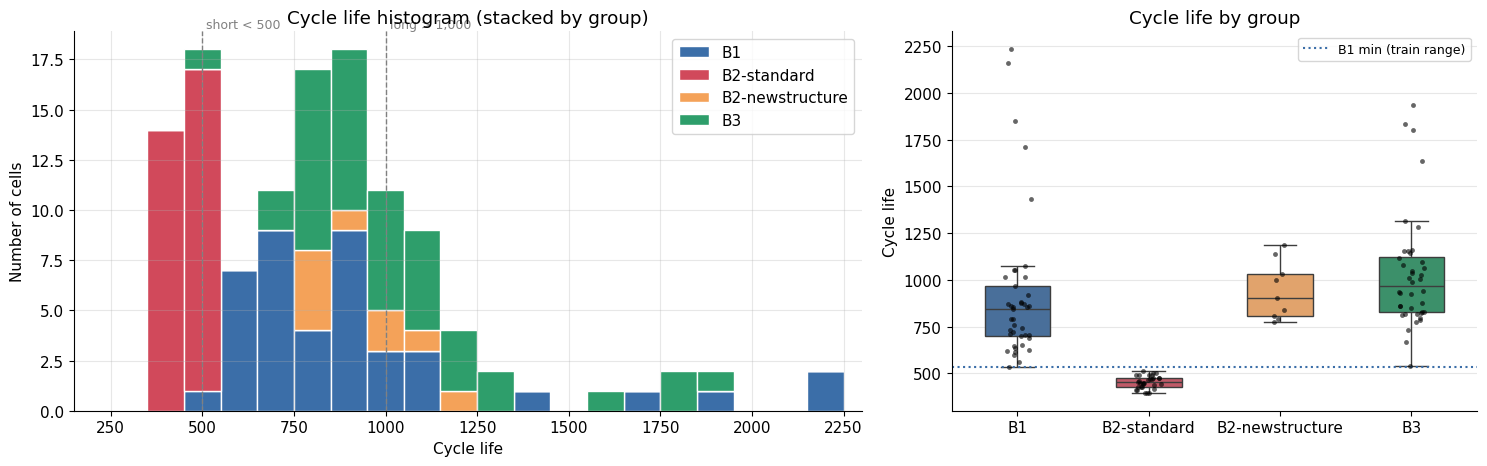

,n,min,median,max,long(>1000),short(<500),label≥550 (장수명)
group,,,,,,,
B1,41,534.000,842.000,"2,237.000",24%,0%,40 / 41
B2-standard,30,392.000,451.000,514.000,0%,93%,0 / 30
B2-newstructure,9,777.000,904.000,"1,186.000",33%,0%,9 / 9
B3,40,541.000,964.500,"1,935.000",48%,0%,39 / 40


Batch 2 셀 중 Batch 1 최솟값(534) 미만 : 30 / 39 → ['B2-standard']


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.5, 1]})

ax = axes[0]
bins = np.arange(150, 2351, 100)
ax.hist([feat.loc[feat.group == g, 'cycle_life'] for g in GROUPS], bins=bins, stacked=True,
        color=[GROUP_COLOR[g] for g in GROUPS], label=GROUPS, edgecolor='white')
for x, t in [(500, ' short < 500'), (1000, ' long > 1,000')]:
    ax.axvline(x, ls='--', c='gray', lw=1)
    ax.text(x, 1.01, t, color='gray', fontsize=9, transform=ax.get_xaxis_transform())
ax.set(xlim=(150, 2300), xlabel='Cycle life', ylabel='Number of cells', title='Cycle life histogram (stacked by group)')
ax.legend()

ax = axes[1]
sns.boxplot(data=feat, x='group', y='cycle_life', order=GROUPS, palette=GROUP_COLOR, ax=ax, showfliers=False, width=.5)
sns.stripplot(data=feat, x='group', y='cycle_life', order=GROUPS, color='k', size=3.5, alpha=.6, ax=ax)
ax.axhline(feat.loc[feat.batch == 1, 'cycle_life'].min(), c=GROUP_COLOR['B1'], ls=':', lw=1.5, label='B1 min (train range)')
ax.set(xlabel='', ylabel='Cycle life', title='Cycle life by group'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

def life_table(df, by):
    g = df.groupby(by)['cycle_life']
    return pd.DataFrame({'n': g.size(), 'min': g.min(), 'median': g.median(), 'max': g.max(),
                         'long(>1000)': g.apply(lambda x: f'{(x > 1000).mean():.0%}'),
                         'short(<500)': g.apply(lambda x: f'{(x < 500).mean():.0%}'),
                         'label≥550 (장수명)': g.apply(lambda x: f'{(x >= 550).sum()} / {len(x)}')})

display(life_table(feat, 'group').reindex(GROUPS))

b1_min = feat.loc[feat.batch == 1, 'cycle_life'].min()
below = feat[(feat.batch == 2) & (feat.cycle_life < b1_min)]
print(f'Batch 2 셀 중 Batch 1 최솟값({b1_min:.0f}) 미만 : {len(below)} / {(feat.batch == 2).sum()} → {below.group.unique().tolist()}')

**[그래프 해석]**
- **Batch 1** : 534 ~ 2,237 (중앙값 842), 오른쪽 꼬리가 긴 분포입니다. 장수명(>1,000) 24%, 단수명(<500) **0개**입니다.
- **Batch 2** : 두 집단으로 나뉩니다. `standard` 30개는 **392 ~ 514 에 몰려 있고**(단수명 93%), `newstructure` 9개는 777 ~ 1,186 입니다.
- **Batch 3** : 전부 `newstructure`, 541 ~ 1,935 (중앙값 964)로 Batch 1과 비슷한 범위입니다.
- 과제 안내의 "Batch 1/2 유사, Batch 3 상이"와 달리, **실제로 이질적인 배치는 Batch 2** 입니다.
- 분류 기준(550)으로 나누면 Batch 1 은 **장수명 40 / 단수명 1** 로, 단수명 클래스를 학습할 수 없습니다.

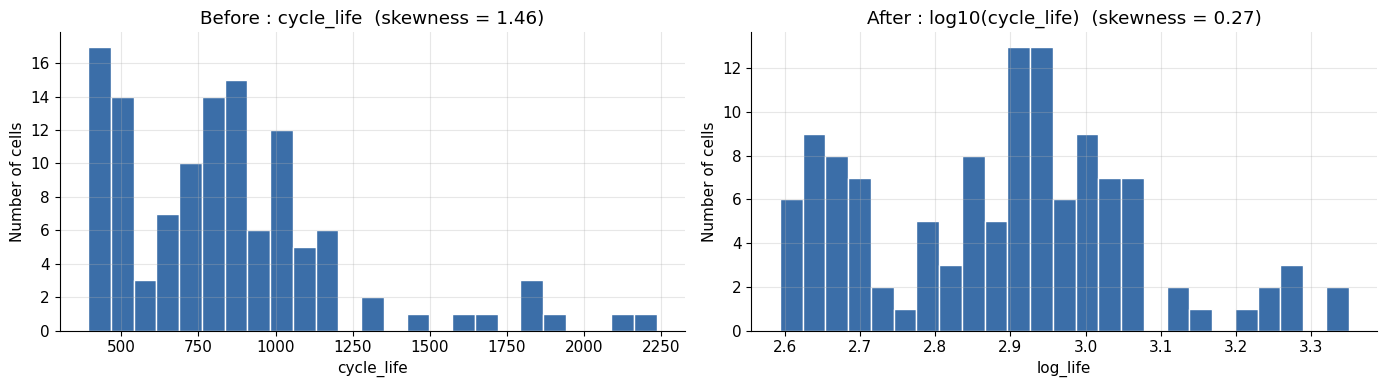

In [6]:
# Target 변환 전/후 : cycle_life vs log10(cycle_life)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, t in [(axes[0], 'cycle_life', 'Before : cycle_life'), (axes[1], 'log_life', 'After : log10(cycle_life)')]:
    ax.hist(feat[col], bins=25, color='#3B6EA8', edgecolor='white')
    ax.set(title=f'{t}  (skewness = {skew(feat[col]):.2f})', xlabel=col, ylabel='Number of cells')
plt.tight_layout(); plt.show()

**[해석]** 수명은 392 ~ 2,237(약 5.7배 범위)의 오른쪽 꼬리 분포로 왜도가 **1.46** 이지만, `log10` 변환 후 **0.27** 로 대칭에 가까워집니다. 원논문도 log 수명을 타깃으로 사용합니다.

In [7]:
# 이상치 셀 : 배치 내 log(cycle_life) 기준 1.5 IQR 밖
def iqr_outliers(df):
    out = []
    for b, g in df.groupby('batch'):
        q1, q3 = g['log_life'].quantile([.25, .75]); r = q3 - q1
        out.append(g[(g.log_life < q1 - 1.5 * r) | (g.log_life > q3 + 1.5 * r)])
    return pd.concat(out)

display(iqr_outliers(feat)[['cell_key', 'group', 'policy', 'cycle_life', 'curve_truncated']])
print('Batch 1 최단 수명 셀 :')
display(feat[feat.batch == 1].nsmallest(3, 'cycle_life')[['cell_key', 'policy', 'C_avg_0_80', 'cycle_life']])

,cell_key,group,policy,cycle_life,curve_truncated
0,b1c0,B1,3.6C(80%)-3.6C,"1,852.000",True
1,b1c1,B1,3.6C(80%)-3.6C,"2,160.000",True
2,b1c2,B1,3.6C(80%)-3.6C,"2,237.000",True
4,b1c4,B1,4C(80%)-4C,"1,709.000",True
48,b2c7,B2-newstructure,4.8C(80%)-4.8C-newstructure,777.000,False
49,b2c8,B2-newstructure,5.2C(58%)-4C-newstructure,904.000,False
50,b2c9,B2-newstructure,5.6C(26%)-4.5C-newstructure,791.000,False
71,b2c32,B2-newstructure,4.8C(80%)-4.8C-newstructure,809.000,False
72,b2c33,B2-newstructure,5.2C(58%)-4C-newstructure,"1,140.000",False
73,b2c34,B2-newstructure,5.6C(26%)-4.5C-newstructure,"1,186.000",False


Batch 1 최단 수명 셀 :


,cell_key,policy,C_avg_0_80,cycle_life
16,b1c20,5.4C(80%)-5.4C,5.400,534.000
17,b1c21,5.4C(80%)-5.4C,5.400,559.000
40,b1c45,8C(35%)-3.6C,4.741,599.000


**[이상치 셀 — 왜 유독 짧은가?]**
- Batch 1 최단 셀(`b1c20` 534, `b1c21` 559)은 모두 `5.4C(80%)-5.4C` 로, 0→80% 구간을 **가장 높은 C-rate 로 끝까지 충전**하는 정책입니다. 배치 내에서는 고속 충전이 짧은 수명으로 이어집니다.
- Batch 1 의 IQR 상단 이상치는 수명 보정된 `b1c0~b1c2`, `b1c4` (3.6C·4C, 1,709~2,237)로, 가장 느린 충전 정책의 이어측정 셀입니다.
- Batch 2 는 IQR 기준으로 **newstructure 9개 전부가 이상치**로 분류됩니다 → 한 배치 안에 **서로 다른 두 집단**이 섞여 있다는 신호입니다.
- 따라서 Batch 2 의 짧은 셀들은 개별 셀 결함이 아니라 **집단 전체(standard)가 짧은 것**이며, **시험 조건(배치) 차이**로 해석해야 합니다.

**[시사점 → to modeling]**
- 분류 레이블(550)은 Batch 1 에서 단수명이 1개뿐이라 학습이 사실상 불가능합니다 → **회귀 선택**의 직접 근거입니다.
- Batch 2 standard 30개 전부가 학습 범위(≥534) **아래**에 있어, 테스트는 **외삽(extrapolation)** 문제입니다. 학습 범위 안에서만 예측하는 트리 모델은 구조적으로 불리합니다.
- 타깃은 **`log10(cycle_life)`** 를 사용합니다 (왜도 1.46 → 0.27).
- 테스트 성능은 Batch 2 전체와 함께 **standard / newstructure 를 나누어 보고**해야 원인 해석이 가능합니다.

> **시사점 요약** : 학습·테스트 분포가 크게 다르고(테스트 77%가 학습 범위 밖), 분류 레이블이 성립하지 않습니다 → log 수명 회귀 + 외삽 가능한 모델이 필요합니다.

### Q2. 열화 곡선 — 방전 용량은 어떻게 감소하는가?

**ISSUE** : 열화 속도는 일정한가, 가속되는가? 초기 100 사이클의 용량(QD)만으로 수명을 구분할 수 있는가?

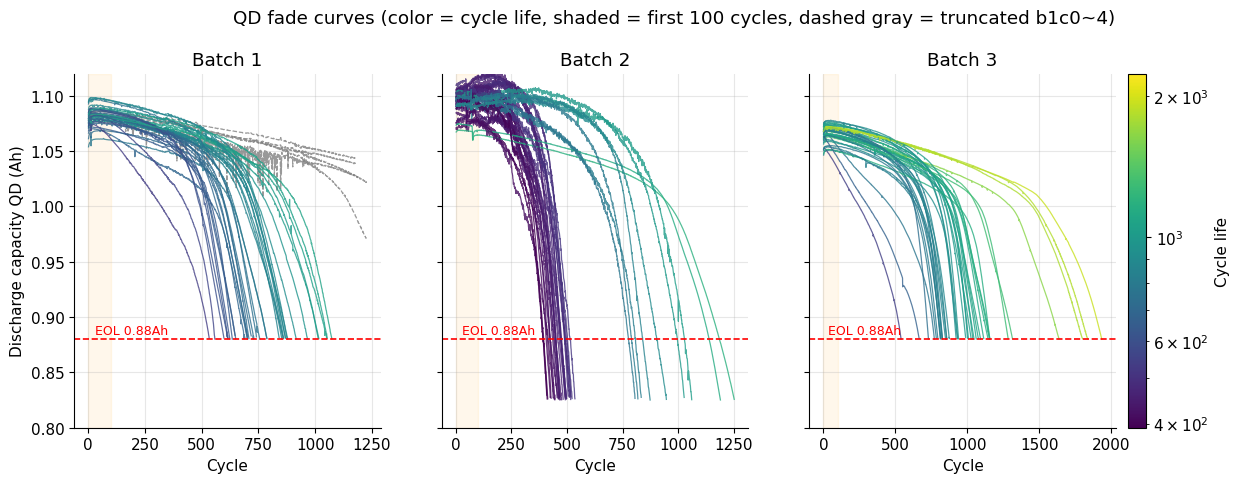

In [8]:
from matplotlib.colors import LogNorm
norm = LogNorm(feat.cycle_life.min(), feat.cycle_life.max())
cmap = plt.cm.viridis

s_ok = summary[~summary.qd_outlier & (summary.cycle_idx >= 1)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, b in zip(axes, [1, 2, 3]):
    for key, g in s_ok[s_ok.batch == b].groupby('cell_key'):
        trunc = g.curve_truncated.iloc[0]
        ax.plot(g.cycle, g.QD, lw=.9, alpha=.8, ls='--' if trunc else '-',
                color='gray' if trunc else cmap(norm(g.cycle_life.iloc[0])))
    ax.axhline(EOL_AH, c='r', ls='--', lw=1.2)
    ax.axvspan(0, 100, color='orange', alpha=.08)
    ax.text(30, EOL_AH + .005, 'EOL 0.88Ah', color='r', fontsize=9)
    ax.set(title=f'Batch {b}', xlabel='Cycle', ylim=(.8, 1.12))
axes[0].set_ylabel('Discharge capacity QD (Ah)')
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, label='Cycle life', pad=.01)
plt.suptitle('QD fade curves (color = cycle life, shaded = first 100 cycles, dashed gray = truncated b1c0~4)', y=1.02)
plt.show()

**[그래프 해석]**
- 모든 배치에서 용량은 **초반 완만 → 후반 급락**하는 비선형 곡선입니다.
- 음영(초기 100 사이클) 구간에서는 수명이 다른 셀들의 곡선이 거의 겹쳐 있습니다 → 초기 QD 값만으로는 수명 구분이 어렵습니다.
- Batch 2 standard 셀(보라색)은 초기에 오히려 용량이 상승한 뒤 400 사이클 전후로 급락합니다.

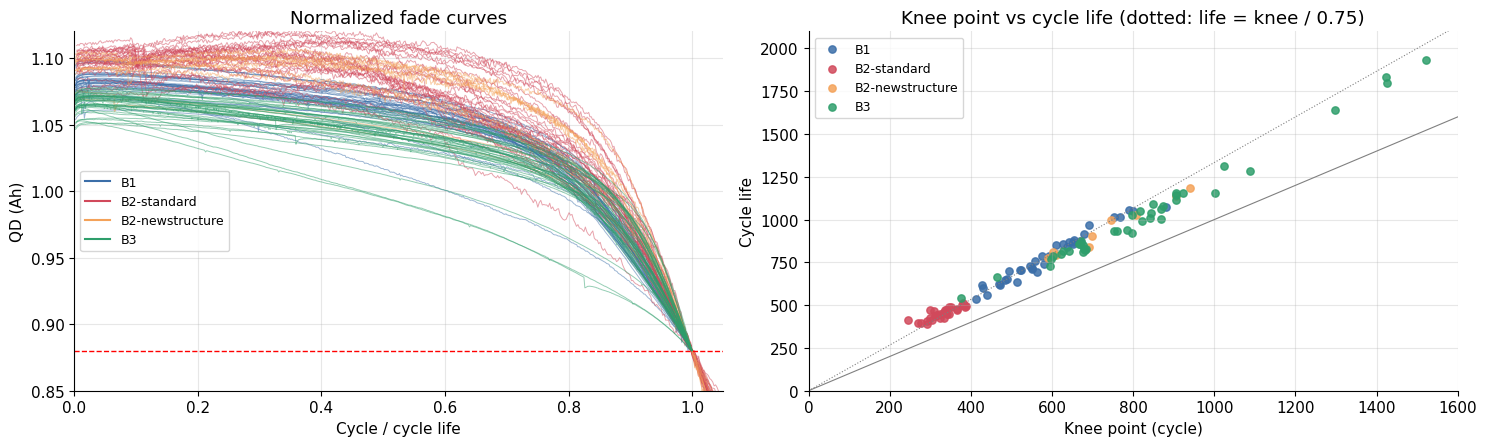

knee 와 수명의 상관 r = 0.99


,knee_cycle,knee / life,slope after / before
group,,,
B1,577.500,0.750,10.411
B2-standard,333.500,0.722,11.138
B2-newstructure,698.000,0.772,16.103
B3,796.000,0.794,10.295


In [9]:
# 수명으로 정규화한 열화 곡선과 knee point
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
s_n = s_ok[~s_ok.curve_truncated].copy()
s_n['life_frac'] = s_n.cycle / s_n.cycle_life
for key, g in s_n.groupby('cell_key'):
    axes[0].plot(g.life_frac, g.QD, color=GROUP_COLOR[g.group.iloc[0]], lw=.7, alpha=.5)
axes[0].axhline(EOL_AH, c='r', ls='--', lw=1)
axes[0].set(xlim=(0, 1.05), ylim=(.85, 1.12), xlabel='Cycle / cycle life', ylabel='QD (Ah)', title='Normalized fade curves')
for g, c in GROUP_COLOR.items():
    axes[0].plot([], [], color=c, label=g)
axes[0].legend(fontsize=9)

knees = knee_table(summary[~summary.curve_truncated]).merge(feat[['cell_key', 'group', 'cycle_life']], on='cell_key')
knees['knee_frac'] = knees.knee_cycle / knees.cycle_life
for g in GROUPS:
    d = knees[knees.group == g]
    axes[1].scatter(d.knee_cycle, d.cycle_life, color=GROUP_COLOR[g], label=g, s=28, alpha=.85)
lim = [0, knees.cycle_life.max() * 1.05]
axes[1].plot(lim, lim, c='gray', lw=.8); axes[1].plot(lim, [l / .75 for l in lim], c='gray', ls=':', lw=.8)
axes[1].set(xlabel='Knee point (cycle)', ylabel='Cycle life', title='Knee point vs cycle life (dotted: life = knee / 0.75)',
            xlim=(0, 1600), ylim=(0, 2100))
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"knee 와 수명의 상관 r = {knees.knee_cycle.corr(knees.cycle_life):.2f}")
display(knees.groupby('group')[['knee_cycle', 'knee_frac', 'accel_ratio']].median().reindex(GROUPS)
        .rename(columns={'knee_frac': 'knee / life', 'accel_ratio': 'slope after / before'}))

**[그래프 해석]**
- 수명으로 정규화하면 배치와 관계없이 열화 곡선의 형태가 거의 겹치고, knee 는 **수명의 약 72~79% 지점**에서 나타납니다 (knee 와 수명 r = 0.99).
- knee 이후 기울기가 knee 이전보다 **약 10~16배** 가파릅니다 → 열화는 일정하지 않고 **가속**됩니다.
- **도메인 관점** : ESS 운영에서 knee 이후에는 용량이 짧은 기간에 급락하므로, 교체 계획은 knee 가 오기 전에 세워야 합니다.

In [10]:
# 구간별 용량 감소 기울기 (×1e-4 Ah/cycle)와 초기 QD 피처의 배치별 상관
fr = fade_rate(summary[~summary.curve_truncated], [(1, 100), (100, 200), (200, 300)]).merge(feat[['cell_key', 'group']], on='cell_key')
display((fr.groupby('group')[['fade_1_100', 'fade_100_200', 'fade_200_300']].median() * 1e4).reindex(GROUPS))

early_cols = ['QD_first', 'QD_slope', 'QD_max_minus_first']
early_r = pd.DataFrame({f'B{b}': d[early_cols].corrwith(d['log_life']) for b, d in feat.groupby('batch')})
display(early_r.style.format('{:+.2f}').set_caption('초기 100 사이클 QD 피처 vs log(cycle life) 상관'))

,fade_1_100,fade_100_200,fade_200_300
group,,,
B1,-0.074,-0.428,-0.585
B2-standard,0.308,-0.124,-3.339
B2-newstructure,-0.545,0.150,-0.396
B3,-0.079,-0.366,-0.445


,B1,B2,B3
QD_first,+0.03,-0.23,+0.26
QD_slope,+0.49,-0.36,+0.43
QD_max_minus_first,+0.56,-0.31,+0.01


**[해석]**
- 초기 100 사이클의 용량 감소 기울기는 0 에 가깝고, B2-standard 는 오히려 양(+, 용량 증가)입니다.
- 초기 QD 피처와 수명의 상관은 배치마다 크기·부호가 다릅니다 (예: `QD_slope` +0.49 / −0.36 / +0.43).

**[시사점 → to modeling]**
- knee 는 수명의 약 75% 시점에서야 관측되므로 **조기 예측 피처로 사용할 수 없습니다** (미래 정보 누설).
- 초기 QD 는 셀 간 차이가 작고 배치마다 상관이 불안정합니다 → **QD 값 자체보다 곡선 형태의 변화(ΔQ(V))** 를 분석합니다 → Q3.

> **시사점 요약** : 열화는 knee 이후 10배 이상 가속되지만 초기 100 사이클의 QD 에는 그 징후가 드러나지 않습니다 → 조기 예측에는 QD 보다 민감한 신호가 필요합니다.

### Q3. ΔQ(V) 곡선 — 초기 사이클에서 차이가 보이는가?

**ISSUE** : QD 총량에는 차이가 없는 초기 100 사이클에서, 전압별 용량 분포의 변화로 장·단수명을 구분할 수 있는가?

`ΔQ₁₀₀₋₁₀(V) = Q_100(V) − Q_10(V)` : 같은 전압에서 방전 용량이 100 사이클 동안 얼마나 변했는지를 전압축(3.5V→2.0V, 1,000점) 전체에서 비교합니다.

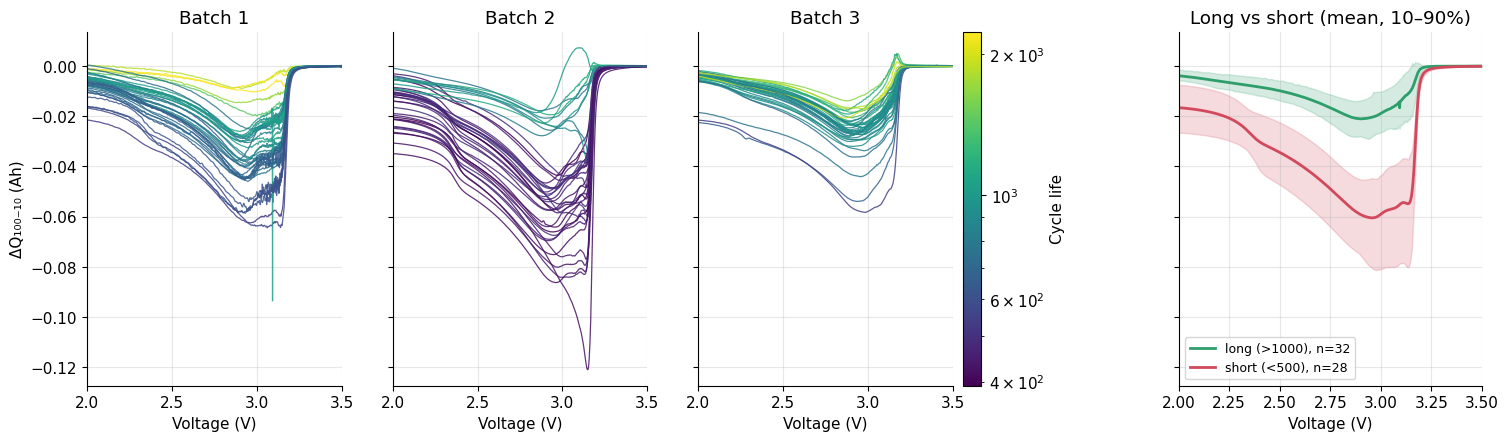

In [11]:
V = qd['V']
dQ = delta_q_matrix(qd, 100, 10)                       # (n_cells, 1000), qd['cell_keys'] 순서
dq_df = pd.DataFrame({'cell_key': qd['cell_keys']}).merge(feat[['cell_key', 'group', 'batch', 'cycle_life']], on='cell_key')

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), sharey=True)
for ax, b in zip(axes[:3], [1, 2, 3]):
    for i in np.flatnonzero(dq_df.batch == b):
        ax.plot(V, dQ[i], color=cmap(norm(dq_df.cycle_life[i])), lw=.9, alpha=.85)
    ax.set(title=f'Batch {b}', xlabel='Voltage (V)', xlim=(2.0, 3.5))
axes[0].set_ylabel('ΔQ₁₀₀₋₁₀ (Ah)')

ax = axes[3]
for lab, m, c in [('long (>1000)', dq_df.cycle_life > 1000, '#2E9E6B'), ('short (<500)', dq_df.cycle_life < 500, '#D1495B')]:
    mu, lo, hi = dQ[m].mean(0), *np.percentile(dQ[m], [10, 90], axis=0)
    ax.plot(V, mu, color=c, lw=2, label=f'{lab}, n={m.sum()}'); ax.fill_between(V, lo, hi, color=c, alpha=.2)
ax.set(title='Long vs short (mean, 10–90%)', xlabel='Voltage (V)', xlim=(2.0, 3.5)); ax.legend(fontsize=9)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes[:3], label='Cycle life', pad=.01)
plt.show()

**[그래프 해석]**
- ΔQ₁₀₀₋₁₀ 곡선은 3.0~3.2V 부근(LFP 방전 평탄 구간)에서 음(−)으로 깊어지며, **수명이 짧을수록(보라색) 곡선이 더 깊고 넓습니다**.
- 장수명(>1,000) vs 단수명(<500) 평균 곡선은 10~90% 밴드가 거의 겹치지 않습니다.
- **도메인 관점** : LFP 는 방전 전압이 평탄해 초기 열화가 총 용량(QD)에는 거의 드러나지 않지만, 전압별 용량 분포는 먼저 변합니다. 원논문은 이를 활물질 손실 등 전극 열화 모드와 연결하여 설명합니다.

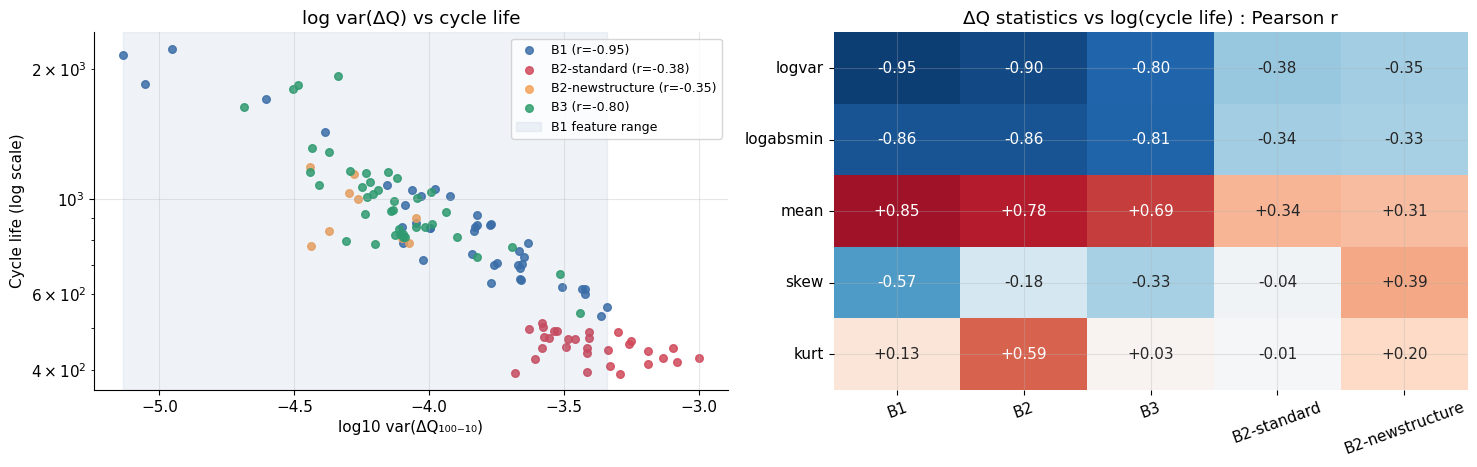

B1 에서 수명 보정 셀(b1c0~4) 제외 시 r = -0.84


,min,median,max
group,,,
B1,-5.136,-3.825,-3.342
B2-standard,-3.682,-3.415,-3.000
B2-newstructure,-4.443,-4.278,-4.049
B3,-4.685,-4.138,-3.441


B1 피처 범위 상한(-3.34) 초과 B2 셀 : 12개 {'B2-standard': 12}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
for g in GROUPS:
    d = feat[feat.group == g]
    ax.scatter(d.dq100_10_logvar, d.cycle_life, color=GROUP_COLOR[g], s=30, alpha=.85,
               label=f'{g} (r={d.dq100_10_logvar.corr(d.log_life):+.2f})')
b1 = feat[feat.batch == 1]
ax.axvspan(b1.dq100_10_logvar.min(), b1.dq100_10_logvar.max(), color=GROUP_COLOR['B1'], alpha=.08, label='B1 feature range')
ax.set(yscale='log', xlabel='log10 var(ΔQ₁₀₀₋₁₀)', ylabel='Cycle life (log scale)', title='log var(ΔQ) vs cycle life')
ax.legend(fontsize=9)

ax = axes[1]
stats = ['dq100_10_logvar', 'dq100_10_logabsmin', 'dq100_10_mean', 'dq100_10_skew', 'dq100_10_kurt']
r = pd.DataFrame({f'B{b}': d[stats].corrwith(d['log_life']) for b, d in feat.groupby('batch')})
for g in ['B2-standard', 'B2-newstructure']:
    r[g] = feat[feat.group == g][stats].corrwith(feat[feat.group == g]['log_life'])
sns.heatmap(r.rename(index=lambda s: s.replace('dq100_10_', '')), annot=True, fmt='+.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, cbar=False)
ax.set_title('ΔQ statistics vs log(cycle life) : Pearson r'); ax.tick_params(axis='y', rotation=0); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

b1_core = feat[(feat.batch == 1) & ~feat.curve_truncated]
print(f'B1 에서 수명 보정 셀(b1c0~4) 제외 시 r = {b1_core.dq100_10_logvar.corr(b1_core.log_life):.2f}')
display(feat.groupby('group')['dq100_10_logvar'].agg(['min', 'median', 'max']).reindex(GROUPS))
out_of_range = feat[(feat.batch == 2) & (feat.dq100_10_logvar > b1.dq100_10_logvar.max())]
print(f'B1 피처 범위 상한({b1.dq100_10_logvar.max():.2f}) 초과 B2 셀 : {len(out_of_range)}개 {out_of_range.group.value_counts().to_dict()}')

**[그래프 해석]**
- 통계값 중 `log var(ΔQ)` 가 가장 강합니다 : 배치 단위 **B1 −0.95, B2 −0.90, B3 −0.80** 로 세 배치 모두 같은 방향이며, 수명 보정 셀을 빼도 B1 r = −0.84 로 유지됩니다.
- `log var` 와 log 수명의 관계가 **거의 선형**입니다.
- B2 하위 집단 내부만 보면 r ≈ −0.35 ~ −0.38 로 약해집니다 → 같은 집단 안에서는 수명 범위가 좁아(standard 392~514) 순위 구분이 어렵고, B2 전체의 강한 상관은 ΔQ 가 standard vs newstructure **집단 간 차이를 잘 구분**하기 때문입니다.
- B2-standard 30개 중 **12개의 `log var` 값이 B1 피처 범위 상한(−3.34)을 넘습니다** → 타깃뿐 아니라 피처 공간에서도 외삽이 필요합니다.

**[시사점 → to modeling]**
- **핵심 피처 = `log10 var(ΔQ₁₀₀₋₁₀)`** : 배치가 달라도 방향과 크기가 유지되는 가장 강한 신호입니다.
- log 수명과 거의 선형이고, 테스트가 피처·타깃 모두 학습 범위 밖이므로 **외삽이 가능한 선형 모델**이 유리합니다.
- 보조 ΔQ 통계(skew, kurt)는 원논문 Discharge model 구성을 따라 후보로 두고, Q5 에서 배치 간 일관성과 다중공선성을 확인한 뒤 선별합니다.

> **시사점 요약** : 초기 100 사이클의 ΔQ(V) 분산이 세 배치 모두에서 수명을 강하게 설명합니다 → 핵심 피처로 채택하고, 선형 관계를 살리는 선형 회귀 계열을 1순위로 둡니다.

### Q4. 충전 조건(C-rate)과 수명의 관계는?

**ISSUE** : 고속 충전 셀이 정말 수명이 짧은가? 충전 정책 정보를 모델 피처로 써도 배치를 넘어 일반화되는가?

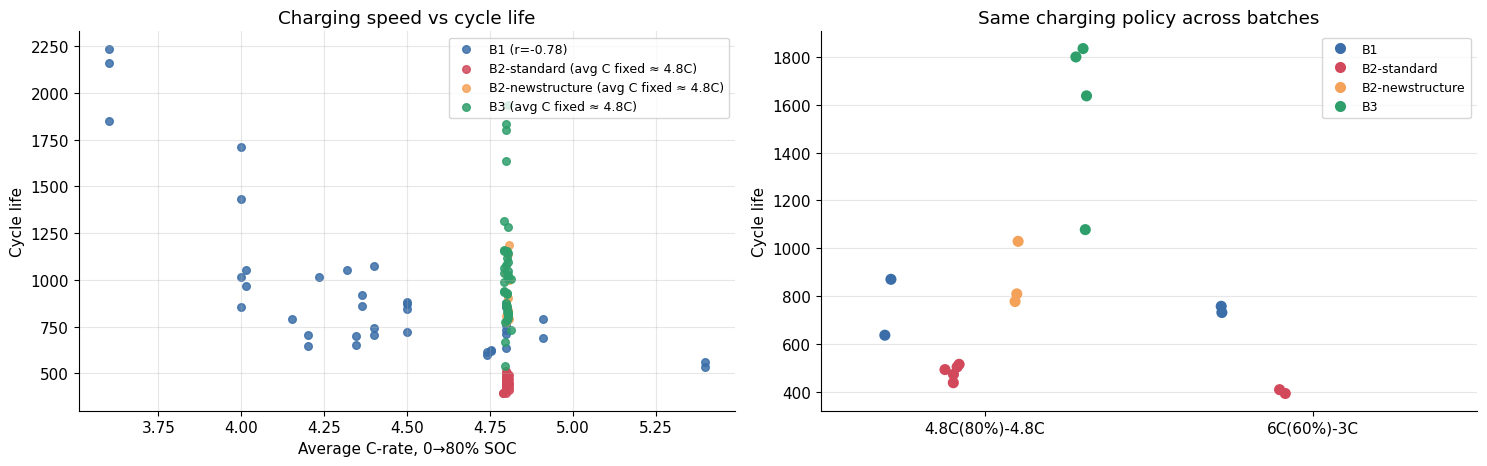

count      mean       min       max
policy_base    group                                               
4.8C(80%)-4.8C B1                   2   753.000   636.000   870.000
               B2-newstructure      3   872.000   777.000 1,029.000
               B2-standard          5   484.000   437.000   514.000
               B3                   4 1,588.000 1,078.000 1,836.000
6C(60%)-3C     B1                   2   744.000   731.000   757.000
               B2-standard          2   400.000   392.000   408.000

B1 r(평균 C-rate, log life) = -0.78, 수명 보정 셀(b1c0~4) 제외 시 = -0.59


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
for g in GROUPS:
    d = feat[feat.group == g]
    fixed = d.C_avg_0_80.std() < .01
    lab = f'{g} (avg C fixed ≈ {d.C_avg_0_80.mean():.1f}C)' if fixed else f'{g} (r={d.C_avg_0_80.corr(d.log_life):+.2f})'
    ax.scatter(d.C_avg_0_80, d.cycle_life, color=GROUP_COLOR[g], s=30, alpha=.85, label=lab)
ax.set(xlabel='Average C-rate, 0→80% SOC', ylabel='Cycle life', title='Charging speed vs cycle life'); ax.legend(fontsize=9)

# 같은 충전 정책의 배치 간 비교 : 정책 효과 vs 배치 효과
ax = axes[1]
shared = ['4.8C(80%)-4.8C', '6C(60%)-3C']
d = feat[feat.policy.str.replace('-newstructure', '').isin(shared)].copy()
d['policy_base'] = d.policy.str.replace('-newstructure', '')
sns.stripplot(data=d, x='policy_base', y='cycle_life', hue='group', hue_order=[g for g in GROUPS if g in d.group.unique()],
              palette=GROUP_COLOR, dodge=True, size=8, ax=ax)
ax.set(xlabel='', ylabel='Cycle life', title='Same charging policy across batches'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

display(d.groupby(['policy_base', 'group'])['cycle_life'].agg(['count', 'mean', 'min', 'max']).round(0))
b1_all = feat[feat.batch == 1]
print(f'B1 r(평균 C-rate, log life) = {b1_all.C_avg_0_80.corr(b1_all.log_life):.2f}, '
      f'수명 보정 셀(b1c0~4) 제외 시 = {b1_core.C_avg_0_80.corr(b1_core.log_life):.2f}')

**[그래프 해석]**
- **Batch 1 내부**에서는 고속 충전일수록 수명이 짧습니다 (평균 C-rate vs log 수명 r = −0.78) → "고속 충전 셀이 정말 수명이 짧은가?" 에 대해 **Batch 1 안에서는 Yes** 입니다. 다만 수명 보정된 저속 충전 셀(b1c0~4)의 영향이 커서, 이들을 빼면 r = −0.59 로 약해집니다.
- **Batch 2·3 은 모든 셀이 0→80% 평균 4.8C(약 10분 충전)로 고정**된 설계입니다. 평균 충전 속도가 같은데도 수명은 392 ~ 1,935 로 약 5배 차이가 납니다.
- **같은 정책, 다른 배치** : `4.8C(80%)-4.8C` 는 B1 636~870, **B2-standard 437~514, B2-newstructure 777~1,029**, B3 1,078~1,836 입니다. **같은 충전 조건에서도 배치/시험 구조에 따라 수명이 2~3배 달라집니다.**

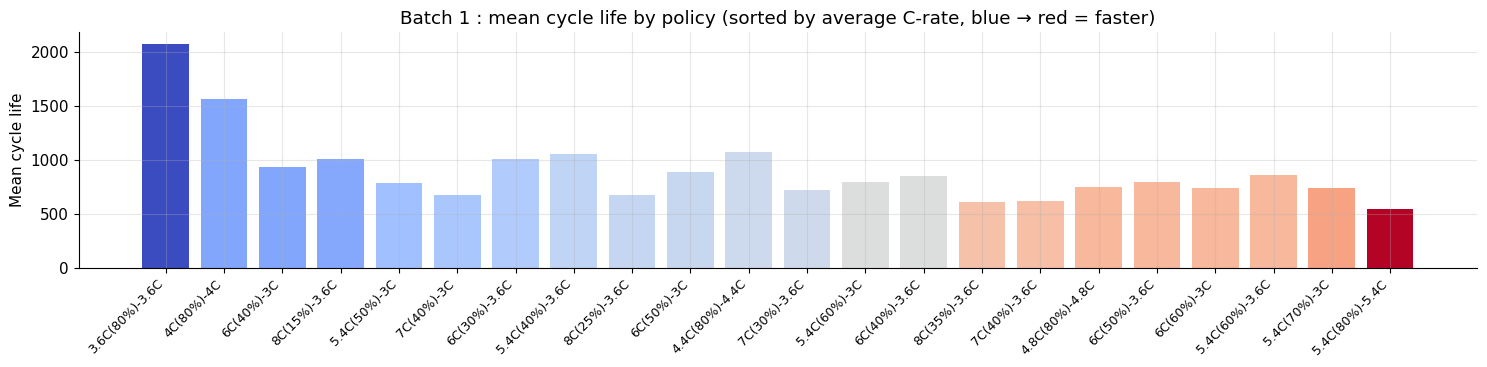

,정책 수,정책 평균 수명 min,정책 평균 수명 max
group,,,
B1,22,546.500,"2,083.000"
B2-standard,9,394.500,483.600
B2-newstructure,3,871.667,991.333
B3,8,660.000,"1,588.250"


,B1,B2,B3
C_avg_0_80 vs fade_1_100,-0.62,-0.31,+0.27
C_avg_0_80 vs fade_200_300,-0.70,+0.33,+0.24
C1 vs fade_1_100,-0.01,+0.14,+0.76
C1 vs fade_200_300,+0.11,+0.28,+0.71


In [14]:
# 충전 프로토콜별 평균 수명 : Batch 1 상세 + 배치별 요약
b1p = (feat[feat.batch == 1].groupby('policy').agg(C_avg=('C_avg_0_80', 'first'), n=('cycle_life', 'size'),
                                                     mean_life=('cycle_life', 'mean')).sort_values('C_avg'))
fig, ax = plt.subplots(figsize=(15, 3.8))
ax.bar(range(len(b1p)), b1p.mean_life, color=plt.cm.coolwarm((b1p.C_avg - b1p.C_avg.min()) / np.ptp(b1p.C_avg)))
ax.set_xticks(range(len(b1p)), b1p.index, rotation=45, ha='right', fontsize=9)
ax.set(ylabel='Mean cycle life', title='Batch 1 : mean cycle life by policy (sorted by average C-rate, blue → red = faster)')
plt.tight_layout(); plt.show()

pol = feat.groupby(['group', 'policy']).cycle_life.mean().groupby('group')
display(pd.DataFrame({'정책 수': pol.size(), '정책 평균 수명 min': pol.min(), '정책 평균 수명 max': pol.max()}).reindex(GROUPS))

# 충전 전류 패턴 vs 구간별 열화 속도
fade = fr.merge(feat[['cell_key', 'C_avg_0_80', 'C1']], on='cell_key')
rows = {b: {f'{x} vs {y}': g[x].corr(g[y]) for x in ['C_avg_0_80', 'C1'] for y in ['fade_1_100', 'fade_200_300']}
        for b, g in fade.assign(batch=fade.group.str[:2]).groupby('batch')}
display(pd.DataFrame(rows).style.format('{:+.2f}').set_caption('충전 전류 패턴 vs 구간별 열화 속도 (Pearson r)'))

**[해석]**
- Batch 1 은 3.6C·4C 정책이 가장 길고 `5.4C(80%)-5.4C` 가 가장 짧습니다. 그러나 같은 평균 C-rate 구간 안에서도 정책 간 수명 차이가 커서, 충전 속도만으로 수명이 결정되지는 않습니다.
- 정책별 평균 수명 범위는 B1 547~2,083, B2-standard 395~484, B2-newstructure 872~991, B3 660~1,588 입니다. B2-standard 는 9개 정책의 평균이 모두 500 미만으로, 정책보다 배치 조건이 수명 수준을 결정합니다.
- 충전 전류 패턴 vs 열화 속도 : B1 은 평균 C-rate 가 높을수록 열화가 빠르지만(r −0.62 / −0.70), B3 는 10분 제약 안에서 **C1(초반 전류)이 높을수록 오히려 열화가 느립니다**(r +0.76 / +0.71) → 충전 패턴 효과의 방향이 배치 설계에 따라 다릅니다.

**[시사점 → to modeling]**
- 충전 정책 피처(`C1`, `Q1`, `C2`, `C_avg`)는 Batch 1 에서만 강하고, 테스트(Batch 2)에서는 평균 C-rate 가 상수라 정보가 거의 없습니다 → **기본 피처셋에서 제외**하고, 비교 실험(+정책 피처)으로만 확인합니다.
- 정책 설정값 대신, 정책이 셀에 남긴 **결과(ΔQ 변화)를 직접 측정한 피처**가 배치 간 일반화에 유리합니다.
- 같은 정책 셀이 train/valid 에 나뉘면 정책 정보가 누설되므로, **정책 단위로 hold-out 을 분리**합니다.

> **시사점 요약** : 수명을 가르는 1차 요인은 충전 정책보다 배치(시험 구조) 조건입니다 → 정책 피처는 배치 과적합 위험이 커서 기본 피처에서 제외합니다.

### Q5. 상관관계 — 어떤 신호가 수명과 연관되어 있는가?

**ISSUE** : 초기 사이클 피처 중 배치를 넘어 안정적으로 수명과 연관된 신호는 무엇이고, 다중공선성 문제는 없는가?

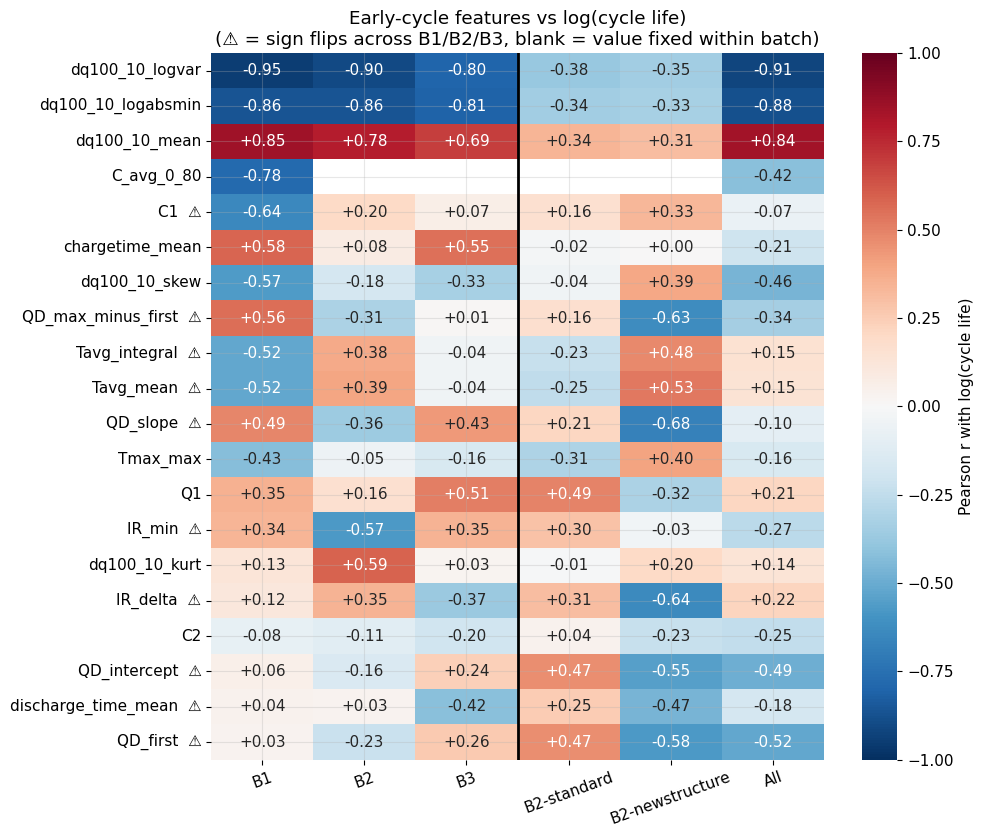

배치 간 부호 일관 피처 : ['dq100_10_logvar', 'dq100_10_logabsmin', 'dq100_10_mean', 'chargetime_mean', 'dq100_10_skew', 'Tmax_max', 'Q1', 'dq100_10_kurt', 'C2']


In [15]:
CANDIDATES = ['dq100_10_logvar', 'dq100_10_logabsmin', 'dq100_10_mean', 'dq100_10_skew', 'dq100_10_kurt',
              'QD_first', 'QD_intercept', 'QD_slope', 'QD_max_minus_first',
              'IR_min', 'IR_delta', 'Tavg_mean', 'Tavg_integral', 'Tmax_max',
              'chargetime_mean', 'discharge_time_mean', 'C_avg_0_80', 'C1', 'Q1', 'C2']

def corr_with_life(d, cols):
    r = d[cols].corrwith(d['log_life'])
    cv = d[cols].std() / d[cols].mean().abs()
    return r.mask(cv < .005)            # 그룹 내 값이 사실상 고정(변동계수 < 0.5%)이면 빈칸 처리

corr = pd.DataFrame({f'B{b}': corr_with_life(d, CANDIDATES) for b, d in feat.groupby('batch')})
sign_flip = np.sign(corr).nunique(axis=1) > 1        # 판정 기준 : 배치(B1/B2/B3) 단위 부호 일관성
for g in ['B2-standard', 'B2-newstructure']:          # 참고 : Batch 2 하위 집단
    corr[g] = corr_with_life(feat[feat.group == g], CANDIDATES)
corr['All'] = corr_with_life(feat, CANDIDATES)
corr = corr.reindex(corr['B1'].abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, annot=True, fmt='+.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, cbar_kws={'label': 'Pearson r with log(cycle life)'})
ax.axvline(3, c='k', lw=2)
ax.set_yticklabels([f'{t.get_text()}  ⚠' if sign_flip[t.get_text()] else t.get_text() for t in ax.get_yticklabels()], rotation=0)
ax.tick_params(axis='x', rotation=20)
ax.set_title('Early-cycle features vs log(cycle life)\n(⚠ = sign flips across B1/B2/B3, blank = value fixed within batch)')
plt.tight_layout(); plt.show()

print('배치 간 부호 일관 피처 :', [c for c in corr.index if not sign_flip[c] and corr.loc[c, ['B1', 'B2', 'B3']].notna().all()])

**[그래프 해석]**
- **가장 강하고 안정적인 신호는 `dq100_10_logvar`** 입니다 : B1 −0.95 / B2 −0.90 / B3 −0.80, 전체 −0.91.
- 배치 간 **부호가 일관된 피처**는 ΔQ 통계(`logvar`, `logabsmin`, `mean`, `skew`, `kurt`), `chargetime_mean`, `Tmax_max`, `Q1`, `C2` 입니다. 이 중 `Q1`, `C2` 는 충전 정책 설정값이므로 Q4 근거에 따라 제외합니다.
- ⚠ 피처(`QD_slope`, `QD_max_minus_first`, `IR_min`, `IR_delta`, `Tavg_*`, `discharge_time_mean`, `QD_first`, `C1`)는 **배치마다 상관 부호가 바뀝니다** → 배치 간 일반화 신호로 보기 어렵습니다. IR 은 Batch 2 의 18% 가 미측정이고, Batch 3 는 측정 펄스폭(33ms vs 30ms)이 달라 배치 간 비교 신뢰도도 낮습니다.

F2 VIF : {'dq100_10_logvar': 2.5, 'dq100_10_skew': 2.3, 'chargetime_mean': 1.8, 'dq100_10_kurt': 1.4}


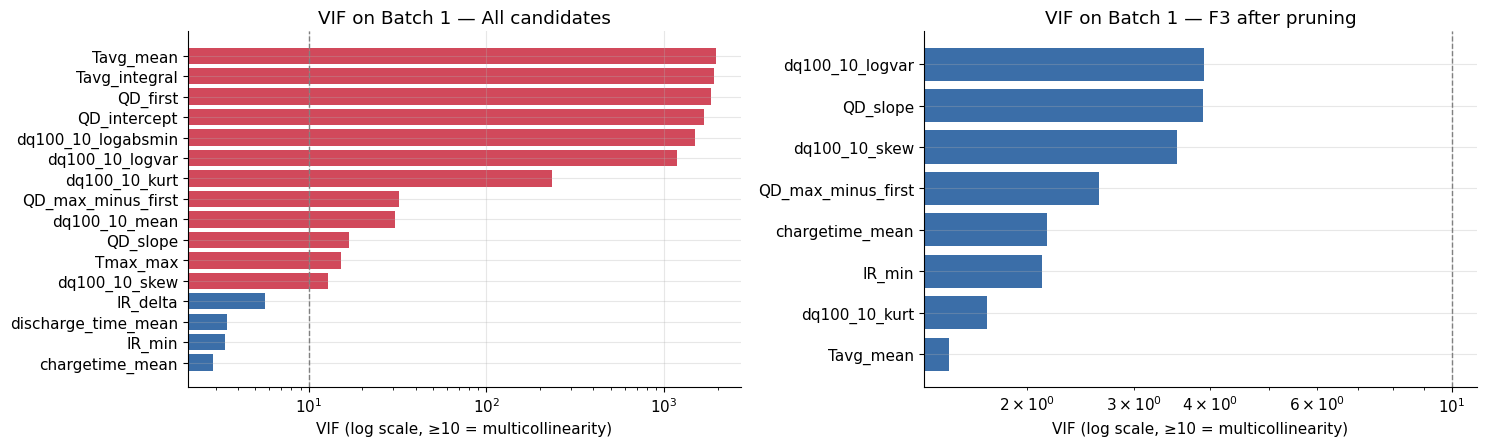

In [16]:
# 다중공선성 (학습셋 Batch 1 기준)
v_all = vif(b1, [c for c in CANDIDATES if c not in ['C_avg_0_80', 'C1', 'Q1', 'C2']])

F1 = ['dq100_10_logvar']
F2 = F1 + ['dq100_10_skew', 'dq100_10_kurt', 'chargetime_mean']                     # 배치 간 부호 일관 피처
F3 = F2 + ['QD_slope', 'QD_max_minus_first', 'IR_min', 'Tavg_mean']                  # + 부호 불일치 피처 (원논문 Full 구성)
v_sel = vif(b1, F3)
print('F2 VIF :', vif(b1, F2).set_index('feature').VIF.round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, v, t in [(axes[0], v_all, 'All candidates'), (axes[1], v_sel, 'F3 after pruning')]:
    ax.barh(v.feature, v.VIF, color=np.where(v.VIF >= 10, '#D1495B', '#3B6EA8'))
    ax.axvline(10, c='gray', ls='--', lw=1); ax.set_xscale('log'); ax.invert_yaxis()
    ax.set(title=f'VIF on Batch 1 — {t}', xlabel='VIF (log scale, ≥10 = multicollinearity)')
plt.tight_layout(); plt.show()

**[그래프 해석]**
- Batch 1 기준 다중공선성 묶음 3개의 VIF 가 수백~수천입니다 : ① 온도(`Tavg_mean`–`Tavg_integral`–`Tmax_max`), ② 초기 용량(`QD_first`–`QD_intercept`), ③ ΔQ 깊이(`logvar`–`logabsmin`–`mean`).
- 묶음별 대표 1개만 남기면 F3 기준 **모든 VIF < 4**, F2 는 **≤ 2.5** 로 낮아집니다.

**[시사점 → to modeling]**
- 피처 선별 원칙 : **① 배치 간 부호 일관성 → ② 공선성 묶음별 대표 1개 → ③ 미래 정보·정책 설정값 제외**
- 이 원칙을 통과한 **F2 = `logvar`, `skew`, `kurt`, `chargetime_mean`** 을 주 피처셋으로, 부호 불일치 피처를 더한 F3 는 배치 과적합 여부를 확인하는 비교군으로 둡니다.
- `Tmax_max` 는 부호는 일관되지만 상관이 약하고(−0.05 ~ −0.43), 데이터 원본이 열전대 접촉 불안정을 명시하고 있어 제외합니다.

> **시사점 요약** : 배치를 넘어 안정적인 신호는 ΔQ 통계와 충전 시간뿐이며, 이를 공선성 없이(VIF ≤ 2.5) 구성한 F2 를 주 피처셋으로 사용합니다.

## 3. EDA → 모델링 전략 연결 요약

| 질문 | 핵심 발견 (근거) | 시사점 | 모델링 결정 |
|---|---|---|---|
| 입력 데이터 | 결측 없음 · B2 IR 18% 미측정 · 세 배치 레이블이 EOL 0.88Ah 정의와 일치 | 레이블 신뢰 가능 · IR 은 비교 신뢰도 낮음 | 원논문 규칙으로 셀 정제, IR=0 은 결측 처리 |
| Q1 분포 | B1 단수명(550 미만) 1/41 · B2-standard 30개 전부 B1 최솟값(534) 미만 · 왜도 1.46 | 분류 학습 불가 · 테스트는 외삽 문제 | **회귀**, 타깃 `log10(cycle_life)`(왜도 0.27), 외삽 가능한 모델 우선 |
| Q1 이상치 | B1 제외 5셀 = 시험 중단 · B2 짧은 셀은 집단 전체가 짧음 | 개별 셀 결함보다 배치 조건 차이 | B2 는 그룹별 성능 분리 보고 |
| Q2 열화 | 초기 100 사이클 QD 평탄, knee 이후 10~16배 가속 · knee ≈ 수명의 75% | 초기 QD 로 구분 어려움 · knee 는 조기 피처 불가 | ΔQ(V) 기반 피처, knee 는 해석용 |
| Q3 ΔQ(V) | `log var(ΔQ₁₀₀₋₁₀)` r = −0.95 / −0.90 / −0.80 · 거의 선형 · B2 일부가 B1 피처 범위 밖 | 배치 간 안정 신호 · 선형 관계 | **핵심 피처** · 선형 모델 1순위 |
| Q4 충전 | B1 내부 r = −0.78 · B2/B3 평균 4.8C 고정인데 수명 5배 차이 · 같은 정책도 배치 간 2~3배 | 정책은 배치 특이적 신호 | 정책 피처 기본 제외 · **정책 단위 hold-out** |
| Q5 상관 | 부호 일관 = ΔQ 통계·충전 시간 · ⚠ QD 기울기·IR·평균 온도 · 공선성 묶음 3개 | 일반화 신호만, 묶음별 대표 1개 | **F2 (VIF ≤ 2.5)** 주 피처셋 · ElasticNet 정규화 |

## 4. 모델 설계 전략

### 4.1 Regression vs Classification → **Regression**
- **Y (Target)** : `log10(cycle_life)` — 꼬리 긴 분포(Q1)와 `log var(ΔQ)` 와의 선형 관계(Q3)를 동시에 만족합니다. 예측 후 `10^ŷ` 로 되돌려 사이클 단위 MAPE 를 계산합니다.
- **Metric / Target** : MAPE, 원논문 **9.1%**
- **분류를 택하지 않은 이유** : 과제 기준(550) 레이블로는 Batch 1 단수명이 1개뿐이라 학습·검증(F1-Score)이 성립하지 않습니다 (Q1). 임계값을 바꾸면 목표 성능(Accuracy 95.1%)과 비교할 수 없습니다.
- **관측 창** : 초기 100 사이클 (`cycle_idx` 1~100). 이후 정보(knee 등)는 사용하지 않습니다.

### 4.2 Feature Engineering (X)

| 피처셋 | 구성 | EDA 근거 | 역할 |
|---|---|---|---|
| **F1 Variance** | `dq100_10_logvar` | Q3 : 세 배치 공통 최강 신호, log 수명과 거의 선형 | 베이스라인 (원논문 Variance model) |
| **F2 Consistent** | F1 + `dq100_10_skew`, `dq100_10_kurt`, `chargetime_mean` | Q5 : 배치 간 부호 일관 + VIF ≤ 2.5 | **주 피처셋** |
| F3 Full | F2 + `QD_slope`, `QD_max_minus_first`, `IR_min`, `Tavg_mean` | Q2·Q5 : B1 에선 유의하나 배치 간 부호 불일치 (VIF < 4) | 비교군 — 배치 과적합 확인 |
| F3 + Policy | F3 + `C_avg_0_80`, `C1`, `Q1`, `C2` | Q4 : B1 에서만 강함, B2 에선 평균 C-rate 상수 | 비교군 — 정책 피처 과적합 확인 |

| 주 피처 (F2) | 의미 | 선정 이유 |
|---|---|---|
| `dq100_10_logvar` | 100 사이클 동안 전압별 방전 용량 변화의 분산(log) | 세 배치 공통 r = −0.80 ~ −0.95, log 수명과 선형 |
| `dq100_10_skew` | ΔQ 곡선 분포의 비대칭도 | 세 배치 모두 음(−)의 상관, logvar 와 공선성 낮음 |
| `dq100_10_kurt` | ΔQ 곡선 분포의 뾰족함 | 세 배치 모두 양(+)의 상관 (B2 +0.59) |
| `chargetime_mean` | 초기 100 사이클 평균 충전 시간 | 세 배치 모두 양(+)의 상관, 정책 설정값이 아닌 측정값 |

- 제외 : `QD_first`/`QD_intercept`(서로 중복 VIF > 1,000, 부호 불일치), `Tavg_integral`/`Tmax_max`(온도 묶음 중복, 측정 불안정), `logabsmin`/`mean`(logvar 와 중복), knee(미래 정보)
- 판단 기준 : F2 대비 F3·F3+Policy 가 **B1 Valid 에서는 좋아지고 Batch 2 에서 나빠지면** 배치 과적합의 증거로 해석합니다.
- 스케일링 : StandardScaler 는 **학습셋(Batch 1)에서만 fit** 하고 Valid/Test 에는 transform 만 적용합니다.

### 4.3 데이터 처리
- 셀 제외 : 원논문 규칙(B1 EOL 미도달 5, B3 노이즈 6) + 수명 레이블이 없는 B2 8셀
- `b1c0~b1c4` : 보정된 수명 레이블을 사용합니다 (초기 100 사이클 데이터는 온전). 열화 곡선 분석에서만 제외합니다.
- 사이클 단위 : `qd_outlier` 행, `cycle_idx 0`(B1 공백 사이클), IR = 0(미측정)을 제외하고 요약 피처를 계산합니다.
- Batch 2 : standard 30 + newstructure 9 를 모두 테스트에 포함하고 **그룹별 MAPE 를 함께 보고**합니다.

### 4.4 후보 모델 (EDA 시사점과 연결)

| 후보 모델 | 선택 이유 (EDA 연결) | 예상 리스크 |
|---|---|---|
| **Linear Regression (F1)** | Q3 : log var(ΔQ) ↔ log 수명이 거의 선형 → 가장 단순한 기준선 | 피처가 1개라 B2-standard 내부 순위 구분이 약함 |
| **ElasticNet (F2)** — 1순위 | Q1·Q3 : 테스트가 학습 범위 밖 → **외삽 가능한 선형 모델**, Q5 : 남은 공선성 + 41셀 소표본 → L1/L2 정규화 | 비선형 관계는 놓칠 수 있음 |
| Huber Regressor (F2) | Q1 : B1 의 긴 꼬리(보정 셀 1,434~2,237)에 덜 민감한 강건 회귀 | 효율 손실 |
| Random Forest / XGBoost (F2) | 비선형·상호작용 확인용 **비교군** | Q1·Q3 : 트리는 학습 범위 밖을 예측하지 못해 B2-standard 를 534 이상으로 예측할 가능성이 높음 (외삽 한계 확인용) |

- **딥러닝을 사용하지 않는 이유** : 학습 셀이 41개뿐이라 과적합 위험이 크고, 핵심 신호(log var ΔQ)가 이미 선형 관계로 잘 요약되어 복잡한 모델의 이점이 작습니다.

### 4.5 검증 방식
- Batch 1 내부 검증은 **충전 정책 단위로 분리**하고(Q4 : 같은 정책 셀이 train/valid 에 섞이면 정책 정보 누설), Batch 2 테스트 성능은 **standard / newstructure 그룹별로 함께 보고**합니다(Q1).